In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report
print("libraries loaded successfully")

libraries loaded successfully


In [3]:
file=r"C:\Users\RSC\Desktop\data sheets\project\data science project\customer_level_features.csv"
df = pd.read_csv(file)
df.head()

,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseTrend,CustomerTenure,Churn
0,C00001,33,2,708.23,354.115,0.0,98,0
1,C00002,41,3,1705.44,568.480,1.0,130,0
2,C00004,96,1,199.66,199.660,-1.0,96,0
3,C00006,74,2,1152.75,576.375,0.0,221,0
4,C00009,42,1,54.88,54.880,NaN,42,1


In [4]:
df['PurchaseTrend'] = df['PurchaseTrend'].fillna(0)

In [5]:
df['AverageOrderValue'] = df['AverageOrderValue'].astype(int)
df['Monetary'] = df['Monetary'].astype(int)
df['PurchaseTrend'] = df['PurchaseTrend'].astype(int)

In [6]:
print(df.dtypes)
print(df.shape)

CustomerID           object
Recency               int64
Frequency             int64
Monetary              int64
AverageOrderValue     int64
PurchaseTrend         int64
CustomerTenure        int64
Churn                 int64
dtype: object
(55, 8)


In [7]:
#target and features
TARGET = "Churn"

feature_columns = [
    "AverageOrderValue",
    "Monetary",
    "PurchaseTrend"
]

x = df[feature_columns].copy()
y = df[TARGET].astype(int)

print(x.shape)
print(y.shape)

(55, 3)
(55,)


In [8]:
#train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Size:", x_train.shape)
print("Testing Size:", x_test.shape)

Training Size: (44, 3)
Testing Size: (11, 3)


In [9]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, feature_columns)
    ]
)
preprocessor.fit(x_train, y_train)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['AverageOrderValue', 'Monetary',
                                  'PurchaseTrend'])])

In [10]:

models = {

    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            ))
        ]
    ),

    "Decision Tree": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=5,
                min_samples_split=20,
                min_samples_leaf=10,
                class_weight="balanced",
                random_state=42
            ))
        ]
    ),

    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                max_depth=8,
                min_samples_split=10,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )
}

In [11]:
results = []
confusion_matrices = {}
trained_models = {}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    model.fit(x_train, y_train)

    trained_models[model_name] = model

    y_pred = model.predict(x_test)
    y_probability = model.predict_proba(x_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, y_probability
    )

    cm = confusion_matrix(y_test, y_pred)

    confusion_matrices[model_name] = cm

    results.append({
        "Model": models,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(cm)


Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.40      0.40         5
           1       0.50      0.50      0.50         6

    accuracy                           0.45        11
   macro avg       0.45      0.45      0.45        11
weighted avg       0.45      0.45      0.45        11

Confusion Matrix:
[[2 3]
 [3 3]]

Training: Decision Tree

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.80      0.57         5
           1       0.50      0.17      0.25         6

    accuracy                           0.45        11
   macro avg       0.47      0.48      0.41        11
weighted avg       0.47      0.45      0.40        11

Confusion Matrix:
[[4 1]
 [5 1]]

Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.60      0.55         5
           1      

In [12]:
# MODEL COMPARISONS
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\n========== MODEL COMPARISON ==========")
print(comparison_df.round(4).to_string(index=False))


FN_COST = 100
FP_COST = 20

business_results = []

for model_name, cm in confusion_matrices.items():

    tn, fp, fn, tp = cm.ravel()

    total_cost = (
        (fn * FN_COST) +
        (fp * FP_COST)
    )

    business_results.append({
        "Model": models,
        "False Positives": fp,
        "False Negatives": fn,
        "False Positive Cost": fp * FP_COST,
        "False Negative Cost": fn * FN_COST,
        "Total Business Cost": total_cost
    })

business_df = pd.DataFrame(business_results)

business_df = business_df.sort_values(
    by="Total Business Cost"
)

print("\n========== BUSINESS COST COMPARISON ==========")
print(business_df.to_string(index=False))



========== MODEL COMPARISON ==========
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [18]:
print("Best model name:", best_model_name)
print("Type:", type(best_model_name))

print("\nTrained models:")
print(trained_models.keys())

Best model name: Random Forest
Type: <class 'str'>

Trained models:
dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest'])


In [14]:
print(business_df.head())
print(business_df.columns)

                                               Model  False Positives  \
2  {'Logistic Regression': (ColumnTransformer(tra...                2   
0  {'Logistic Regression': (ColumnTransformer(tra...                3   
1  {'Logistic Regression': (ColumnTransformer(tra...                1   

   False Negatives  False Positive Cost  False Negative Cost  \
2                3                   40                  300   
0                3                   60                  300   
1                5                   20                  500   

   Total Business Cost  
2                  340  
0                  360  
1                  520  
Index(['Model', 'False Positives', 'False Negatives', 'False Positive Cost',
       'False Negative Cost', 'Total Business Cost'],
      dtype='object')


In [15]:
best_model_name = business_df.iloc[0]["Model"]

print("Best Model Name:", best_model_name)
print("Data Type:", type(best_model_name))

Best Model Name: {'Logistic Regression': Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['AverageOrderValue',
                                                   'Monetary',
                                                   'PurchaseTrend'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))]), 'Decision Tree': Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                     

In [16]:
print(best_model_name)

{'Logistic Regression': Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['AverageOrderValue',
                                                   'Monetary',
                                                   'PurchaseTrend'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))]), 'Decision Tree': Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipe

In [17]:
best_model_name = "Random Forest"

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("Best Model Name:", best_model_name)
print("Data Type:", type(best_model_name))

print("\n========== SELECTED MODEL ==========")
print("best model:", best_model_name)

print(
    "Minimum Estimated Business Cost:",
    business_df.iloc[0]["Total Business Cost"]
)

for model_name in ["Decision Tree", "Random Forest"]:

    classifier = trained_models[model_name].named_steps[
        "classifier"
    ]

    importance_df = pd.DataFrame({
        "Feature": feature_columns,
        "Importance": classifier.feature_importances_
    }).sort_values(
        by="Importance",
        ascending=False
    )

    print(f"\n{model_name} - FEATURE IMPORTANCE")
    print(importance_df.to_string(index=False))

customer_predictions = x_test.copy()

customer_predictions["Actual_Churn"] = y_test

customer_predictions["Predicted_Churn"] = (
    best_model.predict(x_test)
)

customer_predictions["Churn_Probability"] = (
    best_model.predict_proba(x_test)[:, 1]
)

customer_predictions["Churn_Risk"] = pd.cut(
    customer_predictions["Churn_Probability"],
    bins=[-0.001, 0.30, 0.70, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print("\n========== CUSTOMER CHURN PREDICTIONS ==========")
print(customer_predictions.head(10))


Best Model: Random Forest
Best Model Name: Random Forest
Data Type: <class 'str'>

========== SELECTED MODEL ==========
best model: Random Forest
Minimum Estimated Business Cost: 340

Decision Tree - FEATURE IMPORTANCE
          Feature  Importance
    PurchaseTrend    0.673469
         Monetary    0.326531
AverageOrderValue    0.000000

Random Forest - FEATURE IMPORTANCE
          Feature  Importance
AverageOrderValue    0.360715
         Monetary    0.339413
    PurchaseTrend    0.299872

========== CUSTOMER CHURN PREDICTIONS ==========
    AverageOrderValue  Monetary  PurchaseTrend  Actual_Churn  Predicted_Churn  \
10                512       512             -1             0                0   
38                160       321              0             0                1   
18                342       684              0             0                1   
32                238       238              0             1                1   
33                822       822             -1    

In [ ]:
print("Data Type:", type(best_model_name))

In [19]:
OUTPUT_DIR = Path("model_outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True) 

index=False

business_df.to_csv(
    OUTPUT_DIR / "business_cost_comparison.csv",
    index=False
)

customer_predictions.to_csv(
    OUTPUT_DIR / "customer_churn_predictions.csv",
    index=True
)

for model_name, cm in confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Retained", "Actual Churned"],
        columns=["Predicted Retained", "Predicted Churned"]
    )

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + "_confusion_matrix.csv"
    )

    cm_df.to_csv(OUTPUT_DIR / filename)


print("\nAll model comparison results saved successfully!")


All model comparison results saved successfully!



========== GLOBAL FEATURE IMPORTANCE ==========
             Feature  Importance  Importance_STD
2      PurchaseTrend    0.093333        0.106249
1           Monetary    0.086667        0.037118
0  AverageOrderValue   -0.026667        0.092856


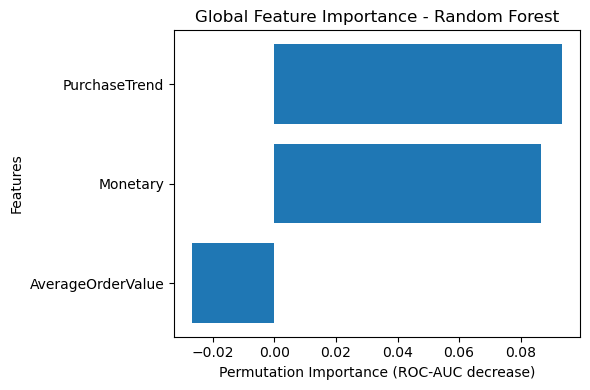


========== TOP 5 CHURN DRIVERS ==========
PurchaseTrend: 0.0933
Monetary: 0.0867
AverageOrderValue: -0.0267

Interpretation: Features with larger positive permutation importance contribute more to model performance. This does not prove causation.

========== SHAP EXPLANATION ==========
SHAP is not installed.
Install it using: pip install shap

========== THREE EXAMPLE PREDICTIONS ==========
   Customer_Index  Actual_Churn  Predicted_Churn  Churn_Probability  \
0              10             0                0              47.21   
1              38             0                1              63.25   
2              18             0                1              55.07   

  Prediction_Result  
0    Likely to Stay  
1   Likely to Churn  
2   Likely to Churn  

========== CUSTOMER FEATURE DETAILS ==========
    AverageOrderValue  Monetary  PurchaseTrend
10                512       512             -1
38                160       321              0
18                342       684            

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score

print("\n========== GLOBAL FEATURE IMPORTANCE ==========")
importance_result = permutation_importance(
    best_model,
    x_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

feature_importance_df = pd.DataFrame({
    "Feature": x_test.columns,
    "Importance": importance_result.importances_mean,
    "Importance_STD": importance_result.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df)

top_features = feature_importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(6, 4))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Permutation Importance (ROC-AUC decrease)")
plt.ylabel("Features")
plt.title(f"Global Feature Importance - {best_model_name}")
plt.tight_layout()
plt.show()

print("\n========== TOP 5 CHURN DRIVERS ==========")

for _, row in feature_importance_df.head(5).iterrows():
    print(
        f"{row['Feature']}: "
        f"{row['Importance']:.4f}"
    )

print(
    "\nInterpretation: Features with larger positive "
    "permutation importance contribute more to model "
    "performance. This does not prove causation."
)

print("\n========== SHAP EXPLANATION ==========")

try:
    import shap
    if hasattr(best_model, "named_steps"):
        preprocessing_step = list(best_model.named_steps.values())[:-1]
        classifier = list(best_model.named_steps.values())[-1]

        preprocessor = best_model[:-1]

        x_test_transformed = preprocessor.transform(x_test)

        try:
            shap_feature_names = preprocessor.get_feature_names_out()
        except Exception:
            shap_feature_names = [
                f"Feature_{i}"
                for i in range(x_test_transformed.shape[1])
            ]

    else:
        classifier = best_model
        x_test_transformed = x_test
        shap_feature_names = x_test.columns.tolist()
        
    sample_size = min(100, x_test.shape[0])

    x_shap = x_test_transformed[:sample_size]

    if hasattr(x_shap, "toarray"):
        x_shap = x_shap.toarray()

    explainer = shap.TreeExplainer(classifier)

    shap_values = explainer.shap_values(x_shap)

    if isinstance(shap_values, list):
        shap_values_to_plot = shap_values[1]
    elif len(np.asarray(shap_values).shape) == 3:
        shap_values_to_plot = np.asarray(shap_values)[:, :, 1]
    else:
        shap_values_to_plot = shap_values

    print("SHAP global feature importance:")

    shap.summary_plot(
        shap_values_to_plot,
        x_shap,
        feature_names=shap_feature_names,
        plot_type="bar",
        show=True
    )

    print("SHAP feature impact summary:")

    shap.summary_plot(
        shap_values_to_plot,
        x_shap,
        feature_names=shap_feature_names,
        show=True
    )

except ImportError:
    print("SHAP is not installed.")
    print("Install it using: pip install shap")

except Exception as e:
    print("SHAP could not be generated:", str(e))
    print("Permutation importance above is still available.")

print("\n========== THREE EXAMPLE PREDICTIONS ==========")

sample_customers = x_test.head(3).copy()

sample_predictions = best_model.predict(sample_customers)

sample_probabilities = best_model.predict_proba(
    sample_customers
)[:, 1]

example_predictions = pd.DataFrame({
    "Customer_Index": sample_customers.index,
    "Actual_Churn": y_test.loc[sample_customers.index].values,
    "Predicted_Churn": sample_predictions,
    "Churn_Probability": sample_probabilities
})

example_predictions["Prediction_Result"] = np.where(
    example_predictions["Predicted_Churn"] == 1,
    "Likely to Churn",
    "Likely to Stay"
)

example_predictions["Churn_Probability"] = (
    example_predictions["Churn_Probability"] * 100
).round(2)

print(example_predictions)
print("\n========== CUSTOMER FEATURE DETAILS ==========")

print(sample_customers)

print("\n========== DATA LEAKAGE REVIEW ==========")

suspicious_keywords = [
    "churn",
    "label",
    "future",
    "target",
    "cancellation",
    "cancelled",
    "exit",
    "outcome"
]

possible_leakage = [
    col for col in x_test.columns
    if any(word in col.lower() for word in suspicious_keywords)
]

if possible_leakage:
    print("WARNING: Review these possible leakage columns:")
    print(possible_leakage)
else:
    print("No obvious leakage-related column names found.")

print("\nAdditional leakage checks:")
print("1. Features must be calculated before the prediction cutoff.")
print("2. Future purchases must not be used as input features.")
print("3. Churned target must not appear in X.")
print("4. CustomerID should not be used as a model feature.")
print("5. Preprocessing must be fitted only on training data.")

print("\nLeakage review is not fully automated.")
print("Verify feature calculation dates and business definitions.")

print("\n========== PROXY VARIABLE REVIEW ==========")

possible_proxy_keywords = [
    "age",
    "gender",
    "income",
    "postcode",
    "zip",
    "postal",
    "country",
    "location",
    "religion",
    "ethnicity",
    "disability"
]

possible_proxy_columns = [
    col for col in x_test.columns
    if any(word in col.lower() for word in possible_proxy_keywords)
]

if possible_proxy_columns:
    print("Review these possible sensitive or proxy features:")
    print(possible_proxy_columns)
else:
    print("No obvious proxy-related column names found.")

print("""
Review questions:
1. Does a feature indirectly reveal sensitive information?
2. Could a feature disadvantage a particular customer group?
3. Is the feature genuinely necessary for churn prediction?
4. Can the feature be removed without significantly affecting performance?

Do not automatically remove a feature based only on its name.
Review its meaning and applicable privacy requirements.
""")

print("\n========== SUBGROUP PERFORMANCE ==========")

group_candidates = [
    "Country",
    "Gender",
    "AgeGroup",
    "Region"
]

available_groups = [
    col for col in group_candidates
    if col in x_test.columns
]

if available_groups:

    subgroup_results = []

    for group_column in available_groups:

        subgroup_data = x_test[group_column]

        for group_value in subgroup_data.dropna().unique():

            mask = subgroup_data == group_value

            if mask.sum() < 20:
                continue

            actual = y_test.loc[mask.index[mask]]
            predicted = best_model.predict(x_test.loc[mask])

            subgroup_results.append({
                "Group": group_column,
                "Category": group_value,
                "Customers": len(actual),
                "Accuracy": accuracy_score(actual, predicted),
                "Precision": precision_score(
                    actual, predicted, zero_division=0
                ),
                "Recall": recall_score(
                    actual, predicted, zero_division=0
                ),
                "F1_Score": f1_score(
                    actual, predicted, zero_division=0
                )
            })

    if subgroup_results:
        subgroup_df = pd.DataFrame(subgroup_results)

        print(subgroup_df.round(3))

    else:
        print("No subgroup had at least 20 customers.")

else:
    print("No suitable subgroup columns found in X_test.")

print("""
Note:
- Small groups are excluded from this basic review.
- Compare recall, precision and false-positive rates across groups.
- Differences require investigation; they do not automatically
  establish unfairness.
""")

print("\n========== PRIVACY REVIEW ==========")

privacy_checks = {
    "CustomerID excluded from model features": (
        "CustomerID" not in x_test.columns
    ),
    "Target excluded from model features": (
        "Churned" not in x_test.columns
    ),
    "Predictions use customer-level records": True,
    "Raw personal identifiers not displayed in examples": True
}

for check, status in privacy_checks.items():
    print(f"{check}: {'PASS' if status else 'REVIEW'}")

print("""
Privacy recommendations:
1. Do not expose customer names, email addresses or phone numbers.
2. Restrict access to customer-level predictions.
3. Store model files and datasets securely.
4. Follow applicable data protection requirements.
5. Define a retention period for customer data.
6. Avoid using predictions for decisions unrelated to churn.
""")
print("\n========== MODEL LIMITATIONS ==========")

limitations = [
    "The dataset is synthetic, not actual retail customer data.",
    "Synthetic churn labels may not represent real customer behaviour.",
    "Feature importance shows association, not causation.",
    "Model performance may change on real-world data.",
    "Random train-test splitting does not measure future time-period performance.",
    "Customer behaviour can change over time.",
    "Business costs of false positives and false negatives need validation.",
    "Subgroup results may be unreliable for small sample sizes."
]

for number, limitation in enumerate(limitations, start=1):
    print(f"{number}. {limitation}")

OUTPUT_DIR = Path("model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

example_predictions.to_csv(
    OUTPUT_DIR / "three_example_predictions.csv",
    index=False
)

if "subgroup_df" in globals():
    subgroup_df.to_csv(
        OUTPUT_DIR / "subgroup_performance.csv",
        index=False
    )

print("\n========== EXPLAINABILITY COMPLETE ==========")
print("Results saved in:", OUTPUT_DIR.resolve())